# 02 - Scenario Discovery

**Scope.** Metadata-only analysis of the nuScenes mini keyframe scenarios in the generated outputs. No images or point clouds are read; sweeps are not included. These analyses are not safety or risk measures.

**Clean environment.** Use Python 3.11 or 3.12. From the repository root, install the project and notebook dependencies with `python -m pip install -e ".[notebooks]"`, then run `python scripts/scenario_intelligence.py extract`. On Colab, clone the repository and install from its root; the notebook reads the generated `scenarios.json` and reports.

The repository root is discovered from the current notebook location; no machine-specific path is embedded.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt

# Locate the project root portably (works from notebooks/ locally; on Colab, clone the repo and run from it).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
OUT = ROOT / "data" / "processed" / "scenario_intelligence"
assert (OUT / "scenarios.json").exists(), "Run: python scripts/scenario_intelligence.py extract"

from scenarioforge.scenario_intelligence import reporting as rep
dataset_id, records = rep.load_scenarios(OUT / "scenarios.json")
print(dataset_id, len(records), "scenarios (keyframe-level metadata only)")

nuscenes:v1.0-mini 404 scenarios (keyframe-level metadata only)


## 1. What is a scenario here?
One scenario = one keyframe sample plus a flat feature mapping. `None` means *not available* and is never imputed.

In [2]:
rec = records[0]
print(json.dumps(rec.to_dict(), indent=1)[:1200])

{
 "sample_id": "cd9964f8c3d34383b16e9c2997de1ed0",
 "scene_id": "2fc3753772e241f2ab2cd16a784cc680",
 "scene_name": "scene-0757",
 "timestamp": 1535657108301401,
 "features": {
  "attribute_counts": {
   "vehicle.moving": 3,
   "vehicle.parked": 5
  },
  "category_combination": "movable_object.trafficcone|vehicle.bus.rigid|vehicle.car|vehicle.construction|vehicle.truck",
  "category_counts": {
   "movable_object.trafficcone": 3,
   "vehicle.bus.rigid": 1,
   "vehicle.car": 5,
   "vehicle.construction": 1,
   "vehicle.truck": 1
  },
  "ego_displacement_m": null,
  "ego_speed_mps": null,
  "ego_x": 334.5398509505576,
  "ego_y": 658.7025312409702,
  "ego_yaw_deg": 164.99511972309136,
  "fraction_low_visibility": 0.0,
  "group_combination": "traffic_related|vehicle",
  "group_counts": {
   "traffic_related": 3,
   "vehicle": 8
  },
  "location": "boston-seaport",
  "n_camera_refs": 6,
  "n_distinct_categories": 5,
  "n_lidar_refs": 1,
  "n_missing_sensor_files": 0,
  "n_objects": 11,
  "n_

## 2. Feature coverage and missing values
The first keyframe of each scene has no previous pose, so motion features are missing by design.

In [3]:
stats = rep.read_json(OUT / 'scenario_statistics.json')
for name, f in stats['features'].items():
    if f['missing']: print(name, 'missing:', f['missing'])
print('category-group object counts:', stats['category_group_object_counts'])

ego_displacement_m missing: 10
ego_speed_mps missing: 10
category-group object counts: {'pedestrian': 5040, 'static_object': 54, 'traffic_related': 3796, 'two_wheeler': 714, 'vehicle': 8934}


## 3. Category distribution

categories: 18
Shannon (bits): 2.478 | normalized: 0.594 | Simpson: 0.741


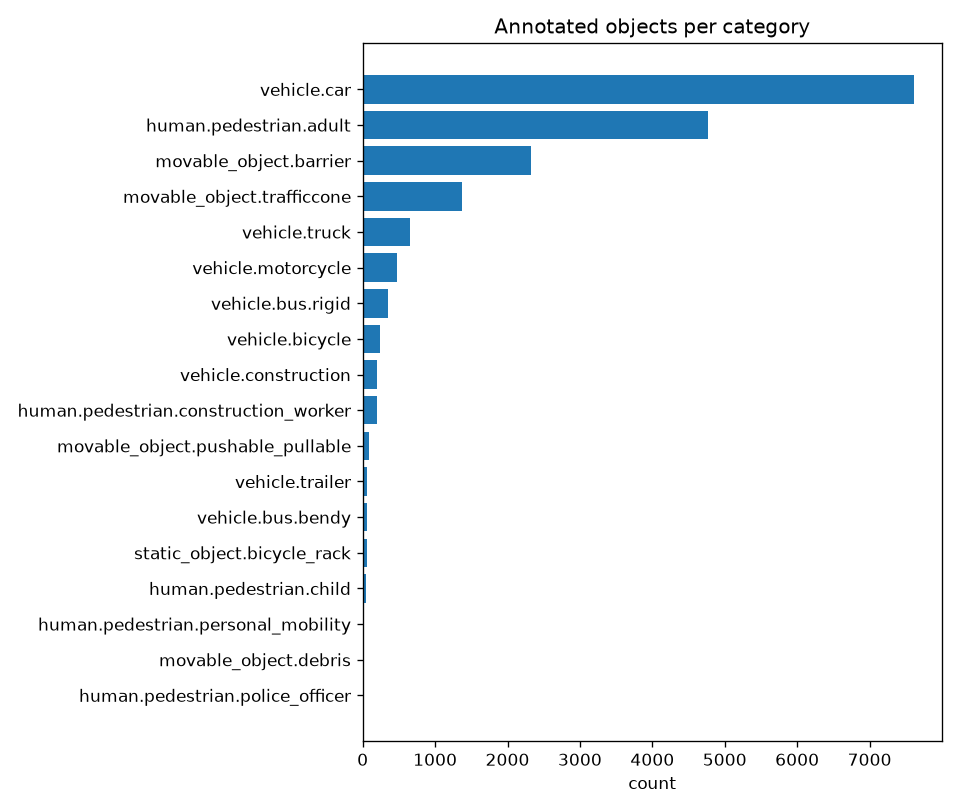

In [4]:
from scenarioforge.scenario_intelligence.diversity_analyzer import object_category_counts
from scenarioforge.scenario_intelligence.metrics import normalized_entropy, simpson_diversity, shannon_entropy
counts = object_category_counts(records)
print('categories:', len(counts))
print('Shannon (bits):', round(shannon_entropy(counts), 3), '| normalized:', round(normalized_entropy(counts), 3), '| Simpson:', round(simpson_diversity(counts), 3))
rep.plot_bar(counts, 'Annotated objects per category', OUT / 'plots' / 'nb_categories.png')
from IPython.display import Image; Image(OUT / 'plots' / 'nb_categories.png')

## 4. Rarity
Rarity is frequency-based: inverse category frequency, combination frequency and binned-feature frequency, each min-max normalized, then averaged. *Rare here means infrequent in this 10-scene dataset, not dangerous.* Combinations default to category **groups**; at full-category level 322 of 404 scenarios were 'rare', which is not informative.

In [5]:
rarity = rep.read_json(OUT / 'rarity_report.json')
print('combination level:', rarity['combination_level'])
print('rare categories:', rarity['rare_categories'])
print('rare combinations:', rarity['rare_combinations'])
print('scenarios in rare combination:', sum(s['is_rare_combination'] for s in rarity['scenario_scores'].values()), 'of', rarity['n_scenarios'])

combination level: group
rare categories: ['human.pedestrian.police_officer', 'movable_object.debris']
rare combinations: ['pedestrian|static_object|traffic_related|vehicle', 'pedestrian|static_object|two_wheeler|vehicle', 'traffic_related|two_wheeler|vehicle', 'two_wheeler|vehicle']
scenarios in rare combination: 60 of 404


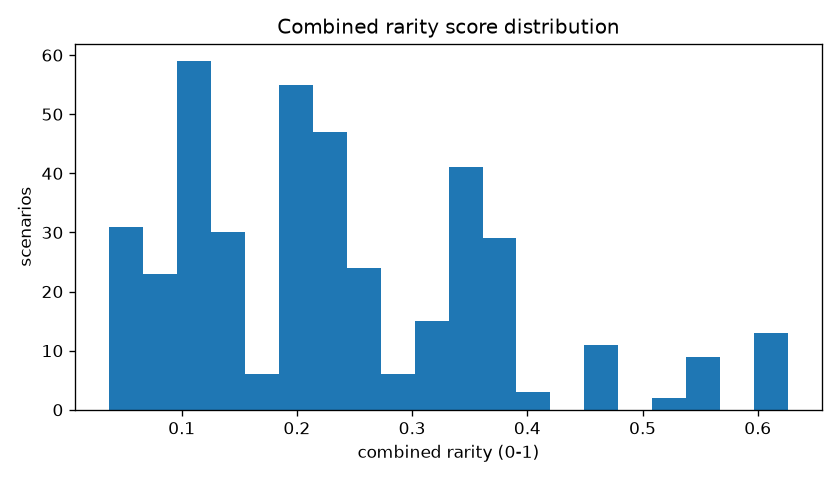

In [6]:
scores = [s["combined"] for s in rarity["scenario_scores"].values() if s["combined"] is not None]
rarity_plot = OUT / "plots" / "nb_rarity_distribution.png"
rep.plot_histogram(scores, "Combined rarity score distribution", "combined rarity (0-1)", rarity_plot)
from IPython.display import Image, display
display(Image(filename=str(rarity_plot)))

## 5. Near-duplicate metadata pairs

Similarity is metadata-only, not visual or point-cloud similarity. The score is a weighted mean of category-set Jaccard, category-count cosine, min-max-scaled numeric cosine, and same-known-location agreement; unavailable numeric/context components are omitted and remaining weights renormalized. Threshold-passing pairs are classified as consecutive, temporally adjacent (within 1 second), non-adjacent within a scene, or cross-scene. The report exposes per-component scores and weighted contributions.

Observed in the saved run: 4,609/4,623 candidates are same-scene, but 4,022 are classified non-adjacent; 381 are consecutive, 206 are temporally adjacent, and 14 are cross-scene. This is evidence that most threshold-passing pairs are not immediate time neighbors, not evidence that they are redundant training data. The optional adjacency exclusion is demonstrated below; it excludes ordinally consecutive pairs even when their timestamp gap exceeds the adjacency window.

In [7]:
from scenarioforge.scenario_intelligence.duplicate_detector import DuplicateConfig, detect_duplicates

dup = detect_duplicates(records, DuplicateConfig(temporal_adjacency_s=1.0))
print("threshold:", dup["similarity_threshold"], "| pairs:", dup["n_near_duplicate_pairs_unfiltered"])
print("pair classes (unfiltered):", dup["pair_classification_counts_unfiltered"])
print("exact duplicate samples:", dup["n_exact_duplicate_samples"])

cross_scene = detect_duplicates(records, DuplicateConfig(scene_scope="cross", temporal_adjacency_s=1.0))
print("cross-scene filter retained:", cross_scene["n_near_duplicate_pairs"], "pairs")
separated = detect_duplicates(records, DuplicateConfig(min_temporal_separation_s=1.0))
print("1-second minimum within-scene separation retained:", separated["n_near_duplicate_pairs"], "pairs")
excluding_adjacent = detect_duplicates(records, DuplicateConfig(exclude_temporally_adjacent=True))
print("excluding consecutive/adjacent pairs retained:", excluding_adjacent["n_near_duplicate_pairs"], "pairs")
print("example component scores:", dup["near_duplicate_pairs"][0]["similarity_components"])

threshold: 0.9 | pairs: 4623
pair classes (unfiltered): {'consecutive': 381, 'temporally_adjacent': 206, 'non_adjacent_same_scene': 4022, 'cross_scene': 14}
exact duplicate samples: 21


cross-scene filter retained: 14 pairs


1-second minimum within-scene separation retained: 4036 pairs


excluding consecutive/adjacent pairs retained: 4036 pairs
example component scores: {'categories': {'similarity': 1.0, 'weight': 1.0, 'weighted_contribution': 0.285714}, 'category_counts': {'similarity': 1.0, 'weight': 1.0, 'weighted_contribution': 0.285714}, 'numeric': {'similarity': 1.0, 'weight': 1.0, 'weighted_contribution': 0.285714}, 'context': {'similarity': 1.0, 'weight': 0.5, 'weighted_contribution': 0.142857}}


## 6. Ranking by scenario-interest score
A transparent weighted heuristic (rarity, composition diversity, complexity, optional preference) for prioritising exploration. Every row carries its components and a text explanation.

In [8]:
rank = rep.read_json(OUT / 'scenario_ranking.json')
print(rank['note'], rank['weights'])
for r in rank['ranking'][:5]:
    print(r['rank'], r['sample_id'][:8], round(r['scenario_interest_score'], 3))
    print('   ', r['explanation'])

Heuristic for prioritising data exploration; not a safety or risk score. {'complexity': 1.0, 'composition_diversity': 1.0, 'preference': 0.0, 'rarity': 1.0}
1 a34fabc7 0.877
    scenario-interest = rarity=1.000 (weight 1, adds 0.333) + complexity=0.910 (weight 1, adds 0.303) + composition_diversity=0.721 (weight 1, adds 0.240)
2 4711bcd3 0.874
    scenario-interest = rarity=0.956 (weight 1, adds 0.319) + complexity=0.946 (weight 1, adds 0.315) + composition_diversity=0.720 (weight 1, adds 0.240)
3 c7806757 0.866
    scenario-interest = rarity=1.000 (weight 1, adds 0.333) + complexity=0.860 (weight 1, adds 0.287) + composition_diversity=0.737 (weight 1, adds 0.246)
4 378a3a3e 0.864
    scenario-interest = rarity=1.000 (weight 1, adds 0.333) + complexity=0.860 (weight 1, adds 0.287) + composition_diversity=0.732 (weight 1, adds 0.244)
5 4246e57f 0.863
    scenario-interest = rarity=1.000 (weight 1, adds 0.333) + complexity=0.847 (weight 1, adds 0.282) + composition_diversity=0.741 (weigh

## 7. Limitations
- Keyframes only; sweeps are not analysed.
- Metadata similarity, not visual or LiDAR similarity.
- Ego speed is a coarse keyframe-to-keyframe estimate (about 2 Hz).
- Ten scenes from three logs, so 'rare' is relative to a very small dataset.
- The interest score is a heuristic; its weights are choices, not learned.